# Heart Attack History in U.S. Adults: Which Associations Survive Adjusting for Age?

**Portfolio project · Python · pandas · seaborn · statsmodels · scikit-learn**

## Why this matters

Health survey data are full of associations that look meaningful until age is taken into account. This notebook analyses **246,022 adult respondents** from what appears to be an extract of the CDC's 2022 Behavioral Risk Factor Surveillance System (BRFSS) (the file does not state its source) and asks which of the usual suspects (smoking, diabetes, weight, sleep, physical activity and others) stay associated with a history of heart attack once age and sex are held constant, and which turn out to be artifacts of age or likely consequences of heart disease.

This is a cross-sectional, self-reported survey with no sampling weights, restricted to respondents who answered every item. It supports descriptive analysis, not clinical advice, and the associations are not causal.

## Summary of findings

1. **Age dominates.** Self-reported heart attack history rises from 0.4% among 18–24 year-olds to 13.6% among those 80 and older, a 36-fold gradient. Men report it more often than women (7.2% vs 3.9%), and the sex gap persists at every age (age-adjusted odds ratio 2.14, 95% CI 2.07–2.22).
2. **Several crude associations are age artifacts.** Flu vaccination looks harmful on its own (odds ratio 1.50) but is null after adjusting for age and sex (0.97). Diabetes falls from 3.76 crude to 2.58 after age and sex and 1.91 after all modelled factors; kidney disease from 3.90 to 2.64 to 1.77; former smoking from 2.32 to 1.66 to 1.44. Other associations strengthen once age is removed, such as depression (1.27 to 1.98 with age and sex).
3. **After full adjustment, the clearest associations** are with smoking (current smokers about 1.9 times the odds of never-smokers), diabetes (1.91), COPD (1.81), kidney disease (1.77) and very short sleep (under 5 hours: 2.03 vs 7–8 hours). Sleep is U-shaped: 5–6 and 9+ hours both sit at 1.27. Obesity (1.16–1.18) is a modest association once other factors are included.
4. **Some "predictors" are really consequences.** Half of heart-attack respondents (50.4%) also report angina and 18.7% a stroke. Chest scans, walking difficulty and self-rated health reflect existing illness, so they are kept out of the risk-factor model.
5. **Age and sex alone give a ROC-AUC of 0.75.** Adding lifestyle and chronic conditions raises it to 0.81, and adding self-rated health and mobility (partly consequences) to 0.84.
6. **State comparisons need age standardisation.** Standardising changes some states' rates by more than a percentage point (Florida 7.6% to 6.6%, Mississippi 5.5% to 6.7%), though the rankings stay broadly similar (Spearman 0.80).

## Questions explored (one section each)

1. What is the shape and quality of the data?
2. Which fields need preparation?
3. How does the outcome vary by age and sex?
4. How do crude prevalences differ across risk factors?
5. Which associations survive adjustment for age, sex and other factors?
6. How do states compare before and after age standardisation?
7. How much does each group of fields add to predicting the outcome?

## Reproducibility

Install dependencies with `pip install -r requirements.txt`. Place `heart_2022_no_nans.csv` in a `data/` folder next to this notebook (or run it on Kaggle with the file attached). Charts are also saved to `images/`.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook', palette='Set2')
plt.rcParams['figure.figsize'] = (10, 5.5)
plt.rcParams['axes.titleweight'] = 'bold'

IMAGE_DIR = Path('images')
IMAGE_DIR.mkdir(exist_ok=True)
pct1 = mtick.PercentFormatter(1.0, decimals=0)


def save_fig(fig, name):
    fig.savefig(IMAGE_DIR / f'{name}.png', dpi=150, bbox_inches='tight')


DATA_PATH = Path('data/heart_2022_no_nans.csv')
if not DATA_PATH.exists():
    candidates = [Path('heart_2022_no_nans.csv')] + list(Path('/kaggle/input').glob('**/heart_2022_no_nans.csv'))
    candidates = [p for p in candidates if p.exists()]
    if candidates:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError('CSV not found. Put heart_2022_no_nans.csv in data/ or update DATA_PATH.')

df = pd.read_csv(DATA_PATH)
print(f'Loaded {DATA_PATH}: {len(df):,} respondents × {df.shape[1]} columns')
display(df.head(3))

Loaded data/heart_2022_no_nans.csv: 246,022 respondents × 40 columns


,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,...,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
0,Alabama,Female,Very good,4.0,0.0,Within past year (anytime less than 12 months ...,Yes,9.0,None of them,No,...,1.60,71.67,27.99,No,No,Yes,Yes,"Yes, received Tdap",No,No
1,Alabama,Male,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,Yes,6.0,None of them,No,...,1.78,95.25,30.13,No,No,Yes,Yes,"Yes, received tetanus shot but not sure what type",No,No
2,Alabama,Male,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,No,8.0,"6 or more, but not all",No,...,1.85,108.86,31.66,Yes,No,No,Yes,"No, did not receive any tetanus shot in the pa...",No,Yes


## 1. Data shape, quality and limits of the sample

The file name says `no_nans`: respondents with any missing answer among these 40 variables were removed. That makes the sample convenient but not representative, and the file carries **no survey weights or design variables**, so every percentage below describes these respondents, not U.S. adults. The data are also a single cross-section: exposures and outcomes were reported at the same time, so the order of events is unknown.

Missing values        : 0


Exact duplicate rows  : 9 (survey rows have no ID, so identical answers can be coincidence)
States/territories    : 54 (respondents per state: 743 to 15,000)
HadHeartAttack        : {'No': 232587, 'Yes': 13435} (prevalence 5.46%)


,PhysicalHealthDays,MentalHealthDays,SleepHours,HeightInMeters,WeightInKilograms,BMI
count,246022.00,246022.00,246022.00,246022.00,246022.00,246022.00
mean,4.12,4.17,7.02,1.71,83.62,28.67
std,8.41,8.10,1.44,0.11,21.32,6.51
min,0.00,0.00,1.00,0.91,28.12,12.02
25%,0.00,0.00,6.00,1.63,68.04,24.27
50%,0.00,0.00,7.00,1.70,81.65,27.46
75%,3.00,4.00,8.00,1.78,95.25,31.89
max,30.00,30.00,24.00,2.41,292.57,97.65


Largest gap between reported BMI and weight/height²: 0.95 (rounding only)
BMI above 50          : 2171 | BMI below 15: 207
Sleep 2 hours or less : 1303 | 16 hours or more: 328
Height above 2.1 m    : 53
Physical-health days  : 62.1% report 0, 7.0% report 30


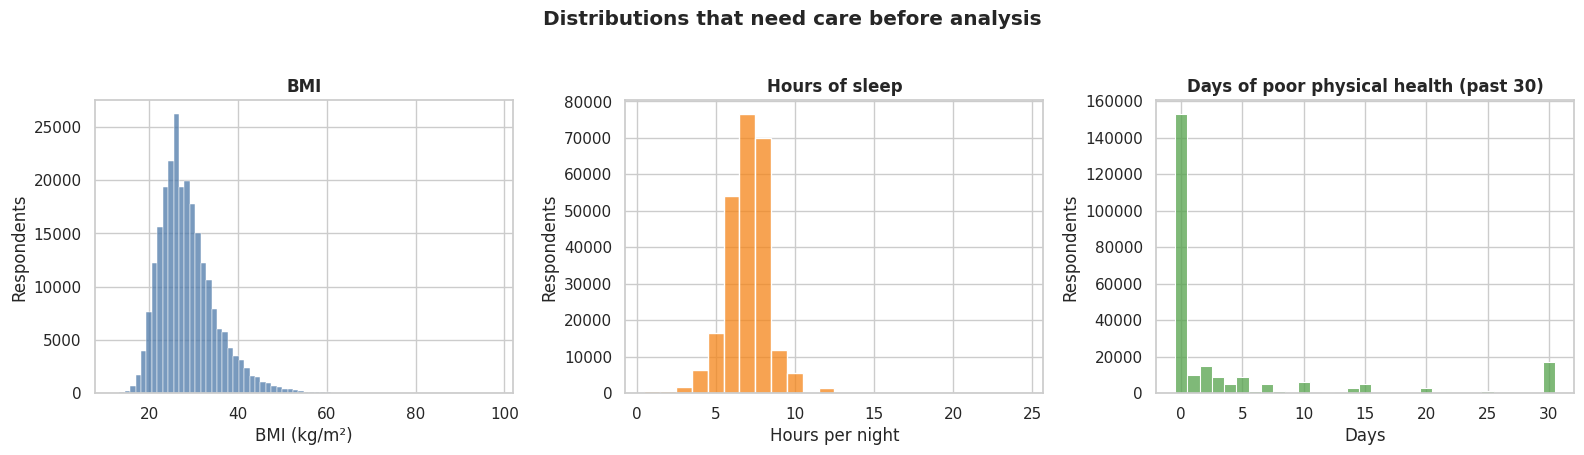

In [2]:
print('Missing values        :', int(df.isna().sum().sum()))
print('Exact duplicate rows  :', int(df.duplicated().sum()), '(survey rows have no ID, so identical answers can be coincidence)')
print('States/territories    :', df['State'].nunique(),
      f"(respondents per state: {df['State'].value_counts().min():,} to {df['State'].value_counts().max():,})")
counts = df['HadHeartAttack'].value_counts()
print('HadHeartAttack        :', counts.to_dict(), f"(prevalence {counts['Yes'] / len(df):.2%})")

display(df[['PhysicalHealthDays', 'MentalHealthDays', 'SleepHours', 'HeightInMeters',
            'WeightInKilograms', 'BMI']].describe().round(2))

bmi_check = (df['WeightInKilograms'] / df['HeightInMeters'] ** 2 - df['BMI']).abs().max()
print(f'Largest gap between reported BMI and weight/height²: {bmi_check:.2f} (rounding only)')
print('BMI above 50          :', int((df['BMI'] > 50).sum()), '| BMI below 15:', int((df['BMI'] < 15).sum()))
print('Sleep 2 hours or less :', int((df['SleepHours'] <= 2).sum()), '| 16 hours or more:', int((df['SleepHours'] >= 16).sum()))
print('Height above 2.1 m    :', int((df['HeightInMeters'] > 2.1).sum()))
print(f"Physical-health days  : {(df['PhysicalHealthDays'] == 0).mean():.1%} report 0, "
      f"{(df['PhysicalHealthDays'] == 30).mean():.1%} report 30")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
sns.histplot(df['BMI'], bins=70, color='#4C78A8', ax=axes[0])
axes[0].set(title='BMI', xlabel='BMI (kg/m²)')
sns.histplot(df['SleepHours'], bins=np.arange(0.5, 25.5, 1), color='#F58518', ax=axes[1])
axes[1].set(title='Hours of sleep', xlabel='Hours per night')
sns.histplot(df['PhysicalHealthDays'], bins=np.arange(-0.5, 31.5, 1), color='#54A24B', ax=axes[2])
axes[2].set(title='Days of poor physical health (past 30)', xlabel='Days')
for ax in axes:
    ax.set_ylabel('Respondents')
fig.suptitle('Distributions that need care before analysis', fontweight='bold', y=1.03)
plt.tight_layout()
save_fig(fig, '01_data_quality_distributions')
plt.show()

**Interpretation:** The file is complete by construction (no missing values), with 9 coincidental duplicate rows that are kept. The outcome, a self-reported history of heart attack, is positive for 13,435 of 246,022 respondents (5.46%). Reported BMI matches weight and height to within rounding. A handful of values are extreme (2,171 respondents with BMI above 50, 1,303 sleeping 2 hours or less, 328 sleeping 16 or more, 53 taller than 2.1 m), so BMI and sleep are grouped into conventional bands instead of being used as raw numbers. Days of poor physical health are piled at 0 (62.1%) and 30 (7.0%), a bimodal pattern that makes the mean misleading. Race and ethnicity are deliberately not analysed here, because without socioeconomic and survey-design context any group comparison would be easy to misread.

## 2. Prepare analysis fields

The original dataframe `df` is never modified. Categories are simplified and ordered, and reference levels are chosen to be the usual comparison group (for example never-smokers, normal BMI, 7–8 hours of sleep).

In [3]:
age_order = ['18–24', '25–29', '30–34', '35–39', '40–44', '45–49', '50–54',
             '55–59', '60–64', '65–69', '70–74', '75–79', '80+']

d = df.copy()
d['heart_attack'] = (d['HadHeartAttack'] == 'Yes').astype(int)
d['age_group'] = (d['AgeCategory'].str.replace('Age ', '', regex=False)
                  .str.replace(' to ', '–', regex=False)
                  .str.replace(' or older', '+', regex=False))
assert set(d['age_group']) == set(age_order)
d['bmi_cat'] = pd.cut(d['BMI'], [0, 18.5, 25, 30, 35, 200], right=False,
                      labels=['Underweight', 'Normal', 'Overweight', 'Obesity I', 'Obesity II+']).astype(str)
d['sleep_cat'] = pd.cut(d['SleepHours'], [0, 5, 7, 9, 25], right=False,
                        labels=['<5', '5-6', '7-8', '9+']).astype(str)
d['diabetes'] = d['HadDiabetes'].map({
    'No': 'No', 'Yes': 'Yes',
    'No, pre-diabetes or borderline diabetes': 'Prediabetes',
    'Yes, but only during pregnancy (female)': 'Gestational only'})
d['smoking'] = d['SmokerStatus'].map({
    'Never smoked': 'Never', 'Former smoker': 'Former',
    'Current smoker - now smokes every day': 'Current daily',
    'Current smoker - now smokes some days': 'Current some days'})
assert d[['diabetes', 'smoking']].notna().all().all()

print('Heart-attack prevalence overall:', f"{d['heart_attack'].mean():.2%}")
display(d[['age_group', 'bmi_cat', 'sleep_cat', 'diabetes', 'smoking']].head(3))


def wilson_ci(k, n, z=1.96):
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half


def rate_table(data, by):
    t = (data.groupby(by, observed=True)['heart_attack']
             .agg(respondents='size', cases='sum', rate='mean').reset_index())
    bounds = [wilson_ci(k, n) for k, n in zip(t['cases'], t['respondents'])]
    t['ci_low'] = [b[0] for b in bounds]
    t['ci_high'] = [b[1] for b in bounds]
    return t

Heart-attack prevalence overall: 5.46%


,age_group,bmi_cat,sleep_cat,diabetes,smoking
0,65–69,Overweight,9+,No,Former
1,70–74,Obesity I,5-6,Yes,Former
2,75–79,Obesity I,7-8,No,Former


## 3. How does the outcome vary by age and sex?

Age is the obvious first stratifier. Men and women are plotted separately with 95% confidence bands.

,respondents,cases,rate,ci_low,ci_high
age_group,,,,,
18–24,13122,50,0.38,0.29,0.50
25–29,11109,47,0.42,0.32,0.56
30–34,13346,90,0.67,0.55,0.83
35–39,15614,156,1.00,0.85,1.17
40–44,16973,228,1.34,1.18,1.53
45–49,16753,420,2.51,2.28,2.75
50–54,19913,703,3.53,3.28,3.80
55–59,22224,1112,5.00,4.72,5.30
60–64,26720,1575,5.89,5.62,6.18


Male vs female prevalence by age group:


Sex,Female,Male,ratio
age_group,,,
18–24,0.23,0.49,2.12
25–29,0.35,0.49,1.39
30–34,0.52,0.83,1.60
35–39,0.79,1.22,1.54
40–44,1.07,1.64,1.53
45–49,2.11,2.93,1.39
50–54,2.66,4.48,1.68
55–59,3.66,6.45,1.76
60–64,4.01,8.04,2.01


Overall: female 3.86% | male 7.19%


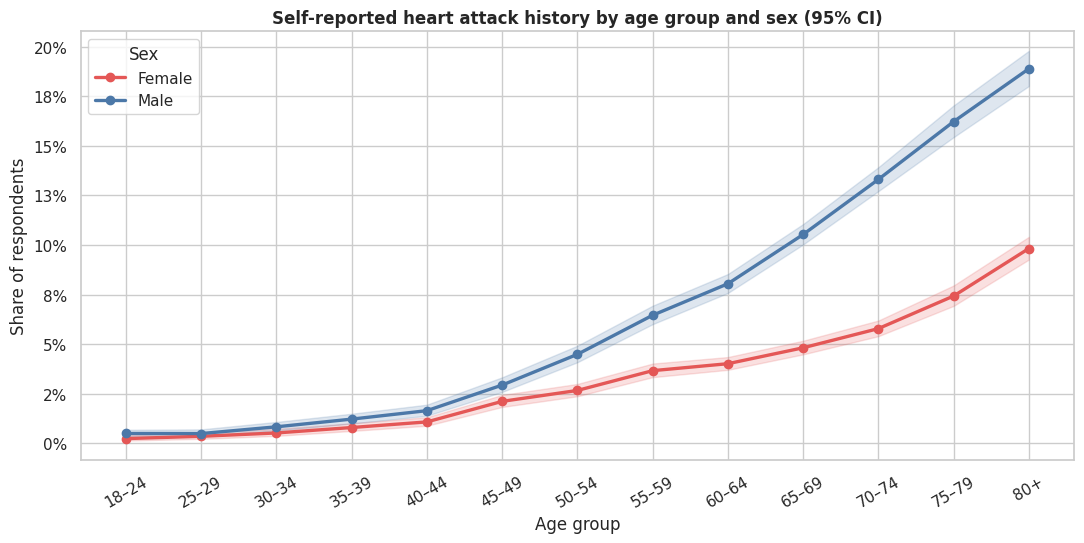

In [4]:
age_sex = rate_table(d, ['age_group', 'Sex'])
overall_age = rate_table(d, 'age_group').set_index('age_group').loc[age_order]
display((overall_age[['respondents', 'cases', 'rate', 'ci_low', 'ci_high']] * [1, 1, 100, 100, 100]).round(2))

wide = age_sex.pivot(index='age_group', columns='Sex', values='rate').loc[age_order]
wide['male_to_female_ratio'] = wide['Male'] / wide['Female']
print('Male vs female prevalence by age group:')
display((wide[['Female', 'Male']] * 100).round(2).assign(ratio=wide['male_to_female_ratio'].round(2)))
print('Overall: female', f"{d.loc[d['Sex'] == 'Female', 'heart_attack'].mean():.2%}",
      '| male', f"{d.loc[d['Sex'] == 'Male', 'heart_attack'].mean():.2%}")

fig, ax = plt.subplots(figsize=(11, 5.6))
for sex, color in [('Female', '#E45756'), ('Male', '#4C78A8')]:
    t = age_sex[age_sex['Sex'] == sex].set_index('age_group').loc[age_order]
    ax.plot(range(len(age_order)), t['rate'], marker='o', linewidth=2.4, color=color, label=sex)
    ax.fill_between(range(len(age_order)), t['ci_low'], t['ci_high'], color=color, alpha=.18)
ax.set_xticks(range(len(age_order)))
ax.set_xticklabels(age_order, rotation=30)
ax.yaxis.set_major_formatter(pct1)
ax.set(title='Self-reported heart attack history by age group and sex (95% CI)',
       xlabel='Age group', ylabel='Share of respondents')
ax.legend(title='Sex')
plt.tight_layout()
save_fig(fig, '02_prevalence_age_sex')
plt.show()

**Interpretation:** Prevalence climbs steadily from 0.38% (18–24) to 13.62% (80 and older), a 36-fold gradient, with prevalence rising about 2.6-fold between 40–44 and 50–54 and roughly 1.6-fold per decade after that. Overall men report heart attack history more often than women (7.19% vs 3.86%), and men are higher in every age group, by about 1.4 to 2.3 times. Because the age mix differs between men and women and between most other groups, nearly every comparison below needs age held constant.

## 4. Crude prevalence across risk factors

Before adjustment, the raw prevalence in each group, with 95% confidence intervals and group sizes. These are the comparisons a quick look at the data would produce.

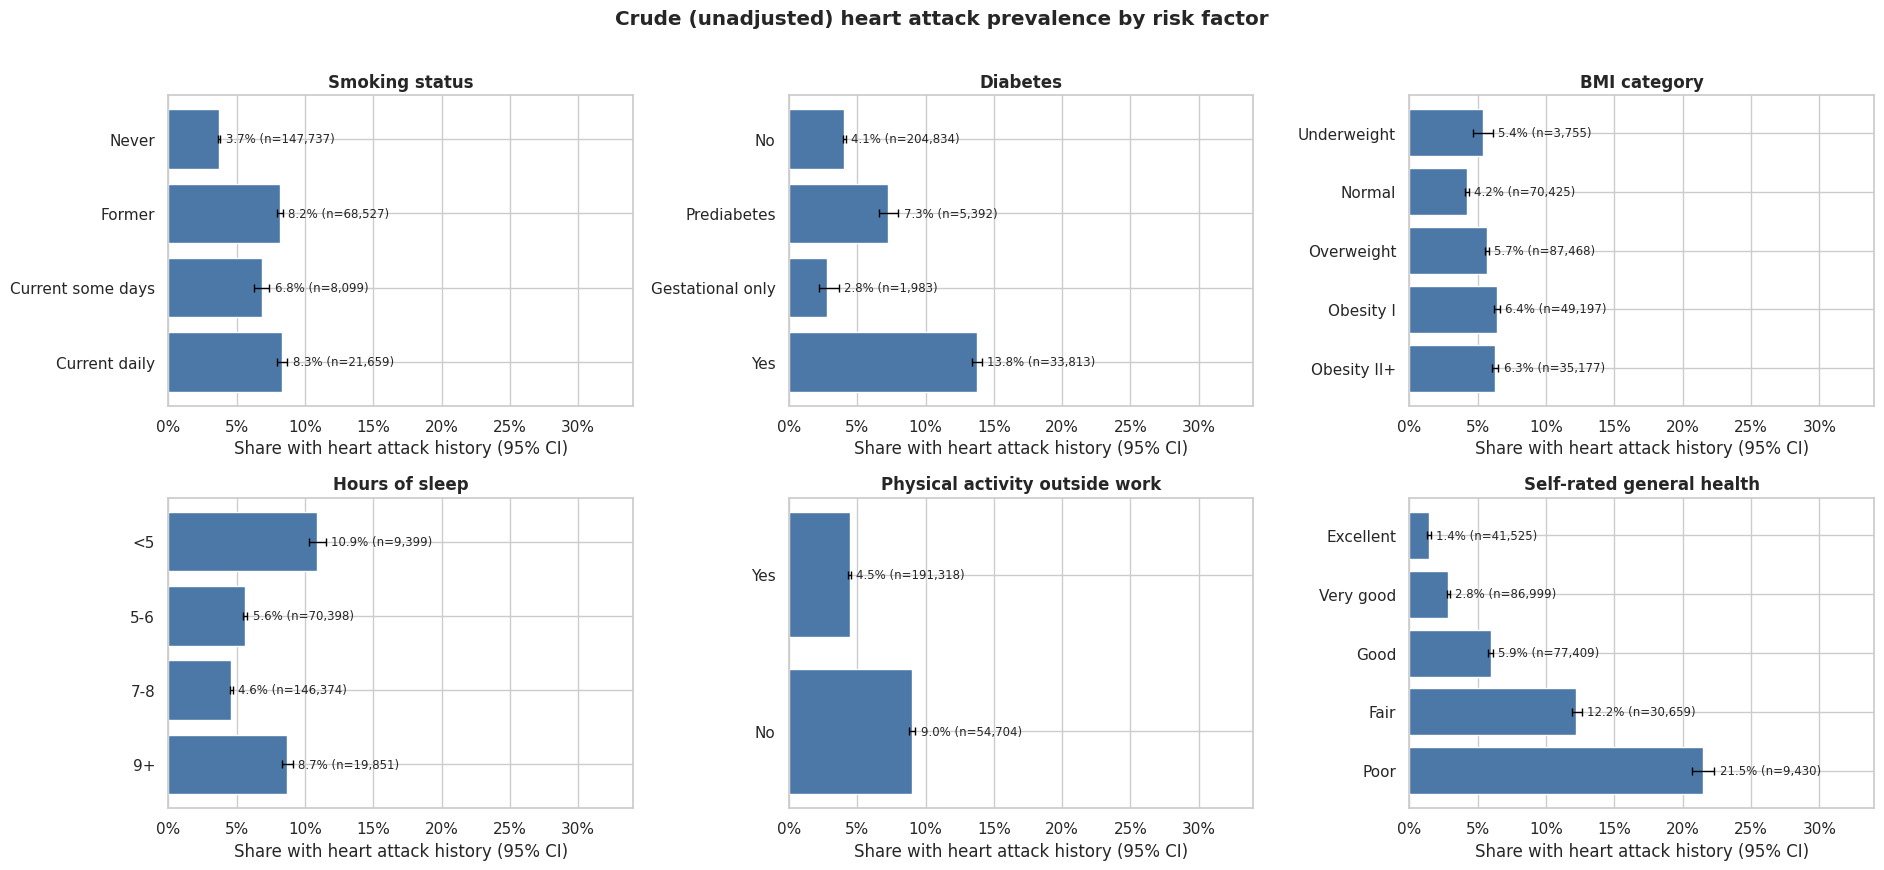

In [5]:
def rate_barh(ax, data, col, order, color):
    t = rate_table(data, col).set_index(col).reindex(order).reset_index()
    y = np.arange(len(t))
    ax.barh(y, t['rate'], color=color)
    ax.errorbar(t['rate'], y, xerr=[t['rate'] - t['ci_low'], t['ci_high'] - t['rate']],
                fmt='none', ecolor='black', capsize=3, linewidth=1)
    for yi, r, hi, n in zip(y, t['rate'], t['ci_high'], t['respondents']):
        ax.text(hi + .004, yi, f'{r:.1%} (n={n:,})', va='center', fontsize=8.5)
    ax.set_yticks(y)
    ax.set_yticklabels(t[col])
    ax.invert_yaxis()
    ax.set_xlim(0, .34)
    ax.xaxis.set_major_formatter(pct1)
    ax.set_xlabel('Share with heart attack history (95% CI)')


panels = [('smoking', 'Smoking status', ['Never', 'Former', 'Current some days', 'Current daily']),
          ('diabetes', 'Diabetes', ['No', 'Prediabetes', 'Gestational only', 'Yes']),
          ('bmi_cat', 'BMI category', ['Underweight', 'Normal', 'Overweight', 'Obesity I', 'Obesity II+']),
          ('sleep_cat', 'Hours of sleep', ['<5', '5-6', '7-8', '9+']),
          ('PhysicalActivities', 'Physical activity outside work', ['Yes', 'No']),
          ('GeneralHealth', 'Self-rated general health', ['Excellent', 'Very good', 'Good', 'Fair', 'Poor'])]
fig, axes = plt.subplots(2, 3, figsize=(19, 8.6))
for ax, (col, title, order) in zip(axes.ravel(), panels):
    rate_barh(ax, d, col, order, '#4C78A8')
    ax.set_title(title)
fig.suptitle('Crude (unadjusted) heart attack prevalence by risk factor', fontweight='bold', y=1.01)
plt.tight_layout()
save_fig(fig, '03_crude_prevalence_factors')
plt.show()

**Interpretation:** Crude gradients are steep for several factors: never-smokers are at 3.7% against 8.2% for former and 8.3% for daily smokers, and people with diabetes are at 13.8% against 4.1% for those without (prediabetes 7.3%). Sleep is U-shaped (under 5 hours 10.9%, 9 or more 8.7%, 7–8 hours 4.6%). BMI shows a modest rise (normal 4.2%, obesity about 6.3–6.4%), and physically active respondents are at 4.5% against 9.0% for inactive ones. Self-rated general health has the steepest gradient (1.4% for excellent to 21.5% for poor), but it is partly a consequence of illness. None of these numbers holds age constant, which is the subject of the next section.

## 5. Which associations survive adjustment?

Each factor is compared with its reference group in three ways: **crude**, **adjusted for age group and sex**, and **fully adjusted** (all ten factors plus age and sex in one logistic regression). Results are odds ratios with 95% confidence intervals. With 246,022 respondents almost everything is statistically significant, so the size of the ratios and how much they move matters more than p-values.

Two groups of fields are treated differently. Flu and pneumococcal vaccination are shown crude and age-adjusted only, because they illustrate confounding rather than being plausible causes. Angina, stroke, chest scans and walking difficulty are shown as a separate panel: they are co-outcomes or likely consequences of heart disease and are not risk factors.

In [6]:
TERM = re.compile(r"C\((\w+), Treatment\('([^']*)'\)\)\[T\.(.*)\]$")
REFS = {'smoking': 'Never', 'diabetes': 'No', 'bmi_cat': 'Normal', 'sleep_cat': '7-8',
        'PhysicalActivities': 'No', 'AlcoholDrinkers': 'No', 'HadKidneyDisease': 'No',
        'HadCOPD': 'No', 'HadDepressiveDisorder': 'No', 'HadArthritis': 'No',
        'FluVaxLast12': 'No', 'PneumoVaxEver': 'No', 'HadAngina': 'No', 'HadStroke': 'No',
        'ChestScan': 'No', 'DifficultyWalking': 'No'}
CORE = ['smoking', 'diabetes', 'bmi_cat', 'sleep_cat', 'PhysicalActivities', 'AlcoholDrinkers',
        'HadKidneyDisease', 'HadCOPD', 'HadDepressiveDisorder', 'HadArthritis']


def term(var):
    return f"C({var}, Treatment('{REFS[var]}'))"


def fit_or(formula):
    res = smf.logit(formula, d).fit(disp=0)
    ci = res.conf_int()
    rows = []
    for name in res.params.index:
        m = TERM.match(name)
        if m:
            var, _, level = m.groups()
            rows.append({'var': var, 'level': level, 'or': np.exp(res.params[name]),
                         'lo': np.exp(ci.loc[name, 0]), 'hi': np.exp(ci.loc[name, 1])})
    return pd.DataFrame(rows)


tables = []
for var in REFS:
    tables.append(fit_or(f'heart_attack ~ {term(var)}').assign(model='Crude'))
    tables.append(fit_or(f'heart_attack ~ {term(var)} + C(age_group) + C(Sex)')
                  .assign(model='Age + sex adjusted'))
full_formula = 'heart_attack ~ C(age_group) + C(Sex) + ' + ' + '.join(term(v) for v in CORE)
tables.append(fit_or(full_formula).assign(model='Fully adjusted'))
or_all = pd.concat(tables, ignore_index=True)

sex_age = smf.logit('heart_attack ~ C(Sex, Treatment("Female")) + C(age_group)', d).fit(disp=0)
name = [n for n in sex_age.params.index if 'Male' in n][0]
ci = sex_age.conf_int().loc[name]
print(f'Male vs female, adjusted for age: OR {np.exp(sex_age.params[name]):.2f} '
      f'(95% CI {np.exp(ci[0]):.2f}–{np.exp(ci[1]):.2f})')

full_fit = smf.logit(full_formula, d).fit(disp=0)
ci_full = full_fit.conf_int().loc['C(Sex)[T.Male]']
print(f"Male vs female, fully adjusted: OR {np.exp(full_fit.params['C(Sex)[T.Male]']):.2f} "
      f'(95% CI {np.exp(ci_full[0]):.2f}–{np.exp(ci_full[1]):.2f})')
age_or = {n.split('[T.')[1].rstrip(']'): np.exp(v) for n, v in full_fit.params.items() if n.startswith('C(age_group)')}
print('Fully adjusted odds ratio for 80+ vs 18–24:',
      f"{age_or['80+']:.1f}", '(CI', ' to '.join(f"{np.exp(x):.1f}" for x in full_fit.conf_int().loc['C(age_group)[T.80+]']) + ')')

Male vs female, adjusted for age: OR 2.14 (95% CI 2.07–2.22)


Male vs female, fully adjusted: OR 2.38 (95% CI 2.29–2.48)
Fully adjusted odds ratio for 80+ vs 18–24: 26.5 (CI 20.0 to 35.2)


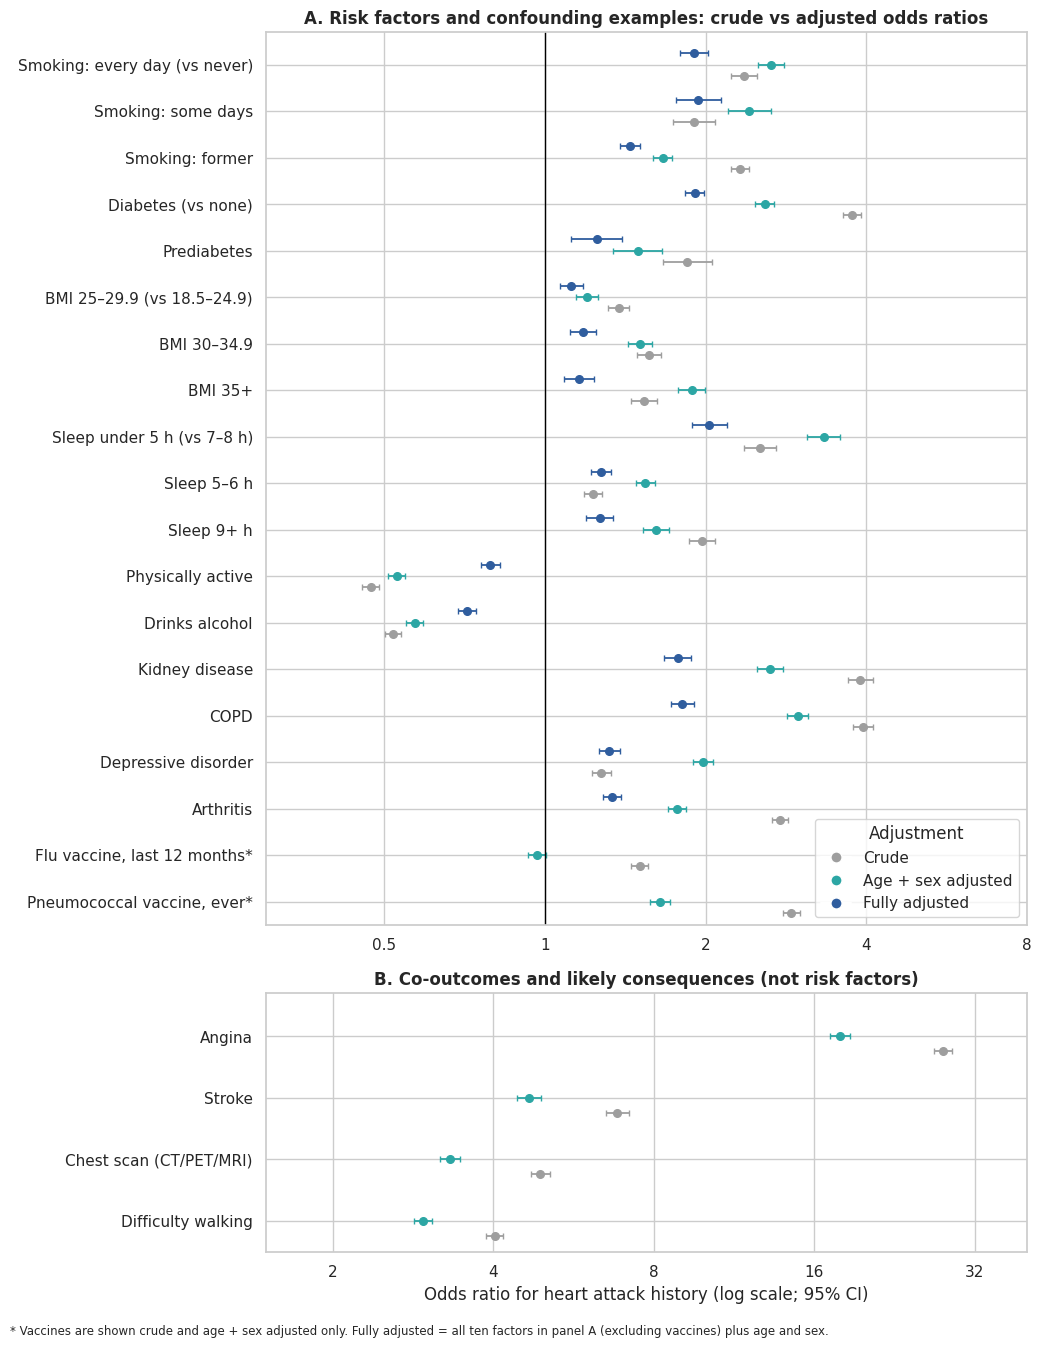

,Crude,Age + sex adjusted,Fully adjusted
factor,,,
Smoking: every day (vs never),2.36 (2.23–2.49),2.65 (2.50–2.81),1.90 (1.79–2.02)
Smoking: some days,1.91 (1.74–2.09),2.42 (2.20–2.65),1.94 (1.76–2.14)
Smoking: former,2.32 (2.23–2.41),1.66 (1.60–1.73),1.44 (1.39–1.50)
Diabetes (vs none),3.76 (3.62–3.91),2.58 (2.48–2.68),1.91 (1.83–1.99)
Prediabetes,1.85 (1.66–2.05),1.49 (1.34–1.66),1.25 (1.12–1.40)
BMI 25–29.9 (vs 18.5–24.9),1.37 (1.31–1.44),1.20 (1.14–1.26),1.12 (1.07–1.18)
BMI 30–34.9,1.57 (1.49–1.65),1.51 (1.43–1.59),1.18 (1.11–1.25)
BMI 35+,1.53 (1.45–1.62),1.88 (1.77–2.00),1.16 (1.09–1.23)
Sleep under 5 h (vs 7–8 h),2.53 (2.36–2.71),3.33 (3.10–3.58),2.03 (1.88–2.20)


Heart attack respondents who also report angina / stroke vs everyone else:
  HadAngina: 50.4% vs 3.5%
  HadStroke: 18.7% vs 3.3%


In [7]:
A_SPECS = [('smoking', 'Current daily', 'Smoking: every day (vs never)'),
           ('smoking', 'Current some days', 'Smoking: some days'),
           ('smoking', 'Former', 'Smoking: former'),
           ('diabetes', 'Yes', 'Diabetes (vs none)'),
           ('diabetes', 'Prediabetes', 'Prediabetes'),
           ('bmi_cat', 'Overweight', 'BMI 25–29.9 (vs 18.5–24.9)'),
           ('bmi_cat', 'Obesity I', 'BMI 30–34.9'),
           ('bmi_cat', 'Obesity II+', 'BMI 35+'),
           ('sleep_cat', '<5', 'Sleep under 5 h (vs 7–8 h)'),
           ('sleep_cat', '5-6', 'Sleep 5–6 h'),
           ('sleep_cat', '9+', 'Sleep 9+ h'),
           ('PhysicalActivities', 'Yes', 'Physically active'),
           ('AlcoholDrinkers', 'Yes', 'Drinks alcohol'),
           ('HadKidneyDisease', 'Yes', 'Kidney disease'),
           ('HadCOPD', 'Yes', 'COPD'),
           ('HadDepressiveDisorder', 'Yes', 'Depressive disorder'),
           ('HadArthritis', 'Yes', 'Arthritis'),
           ('FluVaxLast12', 'Yes', 'Flu vaccine, last 12 months*'),
           ('PneumoVaxEver', 'Yes', 'Pneumococcal vaccine, ever*')]
B_SPECS = [('HadAngina', 'Yes', 'Angina'),
           ('HadStroke', 'Yes', 'Stroke'),
           ('ChestScan', 'Yes', 'Chest scan (CT/PET/MRI)'),
           ('DifficultyWalking', 'Yes', 'Difficulty walking')]
MODELS = [('Crude', '#9E9E9E', .24), ('Age + sex adjusted', '#2CA6A4', 0), ('Fully adjusted', '#2F5D9E', -.24)]


def lookup(var, level, model):
    row = or_all[(or_all['var'] == var) & (or_all['level'] == level) & (or_all['model'] == model)]
    return None if row.empty else row.iloc[0]


def forest(ax, specs, xlim):
    for i, (var, level, label) in enumerate(specs):
        for model, color, off in MODELS:
            r = lookup(var, level, model)
            if r is None:
                continue
            ax.errorbar(r['or'], i + off, xerr=[[r['or'] - r['lo']], [r['hi'] - r['or']]], fmt='o',
                        color=color, capsize=2, markersize=5.5, linewidth=1.3)
    ax.axvline(1, color='black', linewidth=1)
    ax.set_xscale('log')
    ax.set_xlim(*xlim)
    ax.set_yticks(range(len(specs)))
    ax.set_yticklabels([s[2] for s in specs])
    ax.set_ylim(len(specs) - .5, -.7)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set_xticks([x for x in [.25, .5, 1, 2, 4, 8, 16, 32] if xlim[0] <= x <= xlim[1]])
    ax.xaxis.set_minor_locator(mtick.NullLocator())


fig, (axa, axb) = plt.subplots(2, 1, figsize=(10.5, 13.5),
                               gridspec_kw={'height_ratios': [len(A_SPECS), len(B_SPECS) + 1.5]})
forest(axa, A_SPECS, (.3, 8))
axa.set_title('A. Risk factors and confounding examples: crude vs adjusted odds ratios')
forest(axb, B_SPECS, (1.5, 40))
axb.set_title('B. Co-outcomes and likely consequences (not risk factors)')
axb.set_xlabel('Odds ratio for heart attack history (log scale; 95% CI)')
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=8, label=m)
           for m, c, _ in MODELS]
axa.legend(handles=handles, loc='lower right', title='Adjustment')
fig.text(.01, .005, '* Vaccines are shown crude and age + sex adjusted only. Fully adjusted = all ten factors in panel A '
         '(excluding vaccines) plus age and sex.', fontsize=8.5)
plt.tight_layout(rect=(0, .015, 1, 1))
save_fig(fig, '04_crude_vs_adjusted_or')
plt.show()

order_cols = ['Crude', 'Age + sex adjusted', 'Fully adjusted']
rows = []
for var, level, label in A_SPECS + B_SPECS:
    row = {'factor': label}
    for m in order_cols:
        r = lookup(var, level, m)
        row[m] = f"{r['or']:.2f} ({r['lo']:.2f}–{r['hi']:.2f})" if r is not None else ''
    rows.append(row)
display(pd.DataFrame(rows).set_index('factor'))

print('Heart attack respondents who also report angina / stroke vs everyone else:')
for col in ['HadAngina', 'HadStroke']:
    print(f"  {col}: {(d.loc[d['heart_attack'] == 1, col] == 'Yes').mean():.1%} vs "
          f"{(d.loc[d['heart_attack'] == 0, col] == 'Yes').mean():.1%}")

**Interpretation (associations, not causes):**

- **Age artifacts.** Flu vaccination goes from an odds ratio of 1.50 crude to 0.97 after age and sex, and pneumococcal vaccination from 2.90 to 1.64: older people are both vaccinated more and more likely to have had a heart attack. Diabetes drops from 3.76 to 2.58 to 1.91, kidney disease from 3.90 to 2.64 to 1.77, COPD from 3.94 to 2.97 to 1.81 and arthritis from 2.76 to 1.77 to 1.34.
- **Associations that get stronger.** Current daily smokers go from 2.36 crude to 2.65 age-and-sex adjusted, and depressive disorder from 1.27 to 1.98, because respondents with depression are younger (43.5% are under 50, against 33.2% of others). After full adjustment depression falls to 1.32, because it is correlated with the other conditions. Former smokers move the other way (2.32 to 1.66) because they are older: only 25.1% are under 50, against 39.1% of never-smokers.
- **Fully adjusted.** Compared with never-smokers, current smokers have about 1.9 times the odds (1.90 daily, 1.94 some days) and former smokers 1.44. Diabetes is 1.91, COPD 1.81, kidney disease 1.77, and sleeping under 5 hours 2.03 (against 7–8 hours), with both 5–6 and 9+ hours at 1.27. Overweight and obesity are modest (1.12–1.18). Physically active respondents have 0.79 times the odds.
- **Cautions on direction.** Alcohol drinkers show lower odds (0.71 fully adjusted). That is not evidence that drinking protects the heart: people often stop drinking or smoking after a diagnosis, so "non-drinker" and "former smoker" mix cause and consequence. The same reverse-causation problem applies to physical activity.
- **Not risk factors.** Half of heart-attack respondents (50.4%) also report angina, against 3.5% of others, and 18.7% report a stroke (3.3% of others). The very large odds ratios in panel B (angina 27.9 crude) reflect shared disease, not prediction, and chest scans and walking difficulty are things that happen to people who are already unwell. These fields stay out of the risk-factor model.

## 6. State comparisons: raw vs age-standardised

States differ in age structure, so raw prevalence partly reflects who lives there. **Direct age standardisation** applies each state's age-specific rates to one common age distribution (here the pooled age mix of all respondents, not the official U.S. standard population, since the data are unweighted). Confidence intervals use the standard variance formula for a weighted sum of proportions.

The comparison is shown with strong caveats: these are complete-case, unweighted survey respondents, state samples range from a few hundred to 15,000, and the file gives no information on how each state's sample was drawn.

States/territories: 54; raw range 3.36–8.30%, standardised range 3.24–7.96%; Spearman rank correlation of raw vs standardised: 0.80

Lowest standardised rates:


,respondents,raw_%,standardised_%,ci_low_%,ci_high_%,shift_pts
State,,,,,,
Virgin Islands,743.0,3.36,3.24,1.99,4.49,-0.12
District of Columbia,1725.0,3.42,3.66,2.73,4.58,0.24
Hawaii,5596.0,4.45,4.25,3.74,4.77,-0.20
Wyoming,2410.0,5.02,4.48,3.71,5.25,-0.55
Washington,15000.0,4.67,4.52,4.20,4.84,-0.15


Highest standardised rates:


,respondents,raw_%,standardised_%,ci_low_%,ci_high_%,shift_pts
State,,,,,,
West Virginia,2974.0,8.27,7.96,7.03,8.90,-0.31
Arkansas,2940.0,8.30,7.63,6.71,8.54,-0.67
Kentucky,2413.0,6.55,7.19,6.12,8.25,0.64
Tennessee,2725.0,6.50,6.78,5.83,7.73,0.29
South Dakota,4405.0,6.67,6.78,6.04,7.52,0.11


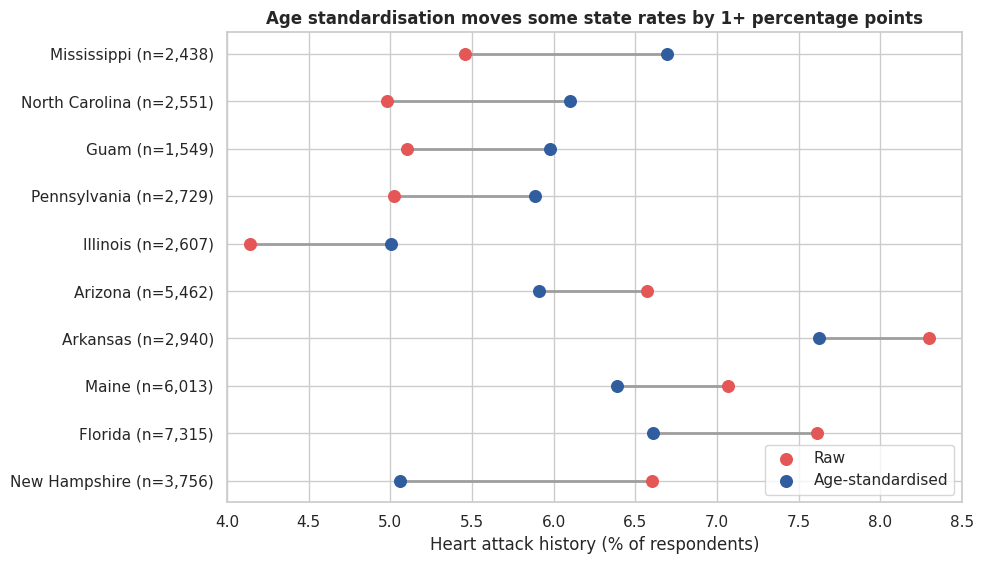

In [8]:
standard = d['age_group'].value_counts(normalize=True)
cells_ = d.groupby(['State', 'age_group'])['heart_attack'].agg(n='size', cases='sum').reset_index()
cells_['p'] = cells_['cases'] / cells_['n']
cells_['w'] = cells_['age_group'].map(standard)


def standardise(g):
    n = g['n'].sum()
    raw = g['cases'].sum() / n
    std = (g['w'] * g['p']).sum()
    se = np.sqrt((g['w'] ** 2 * g['p'] * (1 - g['p']) / g['n']).sum())
    return pd.Series({'respondents': n, 'raw_%': 100 * raw, 'standardised_%': 100 * std,
                      'ci_low_%': 100 * (std - 1.96 * se), 'ci_high_%': 100 * (std + 1.96 * se)})


states = cells_.groupby('State').apply(standardise, include_groups=False)
states['shift_pts'] = states['standardised_%'] - states['raw_%']
rho = states['raw_%'].rank().corr(states['standardised_%'].rank())
print(f"States/territories: {len(states)}; raw range {states['raw_%'].min():.2f}–{states['raw_%'].max():.2f}%, "
      f"standardised range {states['standardised_%'].min():.2f}–{states['standardised_%'].max():.2f}%; "
      f'Spearman rank correlation of raw vs standardised: {rho:.2f}')
print('\nLowest standardised rates:')
display(states.sort_values('standardised_%').head(5).round(2))
print('Highest standardised rates:')
display(states.sort_values('standardised_%', ascending=False).head(5).round(2))

big = states[states['respondents'] >= 1500].sort_values('shift_pts')
pick = pd.concat([big.head(5), big.tail(5)]).sort_values('shift_pts')
fig, ax = plt.subplots(figsize=(10, 5.8))
for i, (name, r) in enumerate(pick.iterrows()):
    ax.plot([r['raw_%'], r['standardised_%']], [i, i], color='#9E9E9E', linewidth=2, zorder=1)
ax.scatter(pick['raw_%'], range(len(pick)), color='#E45756', s=70, label='Raw', zorder=2)
ax.scatter(pick['standardised_%'], range(len(pick)), color='#2F5D9E', s=70, label='Age-standardised', zorder=2)
ax.set_yticks(range(len(pick)))
ax.set_yticklabels([f'{n} (n={int(r["respondents"]):,})' for n, r in pick.iterrows()])
ax.set(title='Age standardisation moves some state rates by 1+ percentage points',
       xlabel='Heart attack history (% of respondents)', xlim=(4, 8.5))
ax.legend(loc='lower right')
plt.tight_layout()
save_fig(fig, '05_state_standardisation')
plt.show()

**Interpretation:** Standardising shrinks the raw spread slightly (3.36–8.30% raw, 3.24–7.96% standardised) and reorders some states: Florida drops from 7.61% to 6.61% and New Hampshire from 6.60% to 5.06% (older populations), while Mississippi rises from 5.46% to 6.69% and North Carolina from 4.98% to 6.10% (younger respondents). The overall ranking is fairly stable (Spearman 0.80). The highest standardised rates are West Virginia (7.96%, 95% CI 7.03–8.90%), Arkansas and Kentucky, and the lowest are the Virgin Islands (3.24%, n = 743, a wide interval), the District of Columbia and Hawaii. Because the samples are unweighted complete cases, these should be read as illustrations of the method, not as state health rankings.

## 7. How much does each group of fields add?

A cross-validated benchmark (5 folds, class-stratified) of logistic regressions on three nested feature sets. This is **not a screening tool**: it shows how much of the outcome each group of fields can explain, using ROC-AUC (0.5 is chance) and PR-AUC (baseline equals the 5.46% prevalence).

,feature_set,roc_auc,pr_auc,roc_sd,pr_sd
0,Age + sex,0.748,0.129,0.004,0.003
1,+ behaviours and chronic conditions,0.811,0.198,0.002,0.003
2,"+ self-rated health, mobility, chest scan",0.836,0.231,0.002,0.003


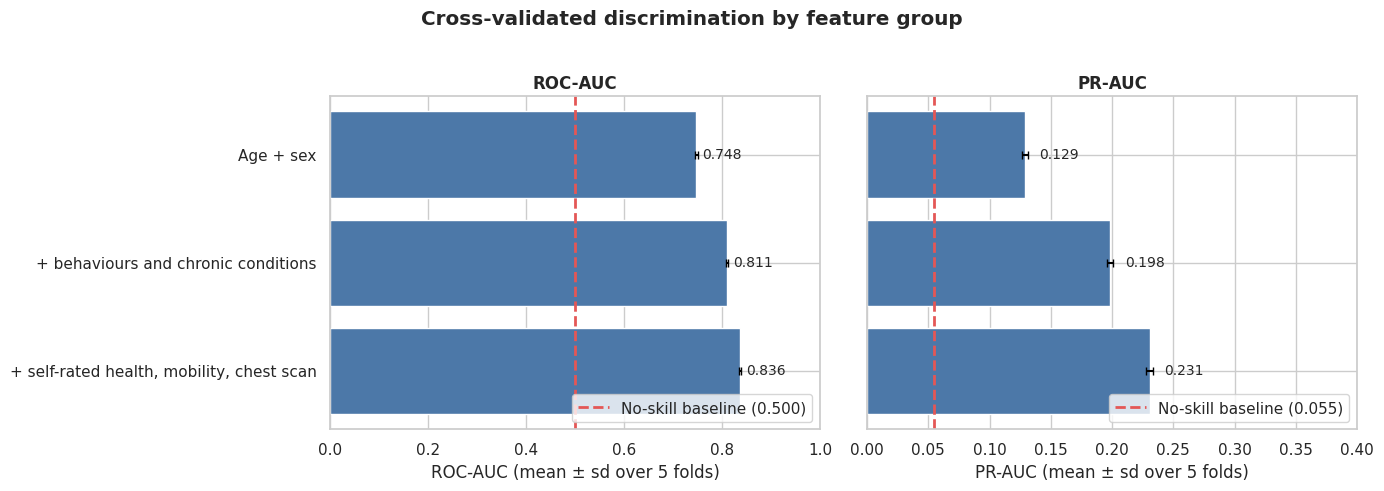

In [9]:
behaviour_cols = ['SmokerStatus', 'diabetes', 'bmi_cat', 'sleep_cat', 'PhysicalActivities',
                  'AlcoholDrinkers', 'HadKidneyDisease', 'HadCOPD', 'HadDepressiveDisorder', 'HadArthritis']
feature_sets = {
    'Age + sex': ['AgeCategory', 'Sex'],
    '+ behaviours and chronic conditions': ['AgeCategory', 'Sex'] + behaviour_cols,
    '+ self-rated health, mobility, chest scan': ['AgeCategory', 'Sex'] + behaviour_cols
                                                 + ['GeneralHealth', 'DifficultyWalking', 'ChestScan'],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
rows = []
for name, cols in feature_sets.items():
    model = make_pipeline(ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cols)]),
                          LogisticRegression(max_iter=3000))
    res = cross_validate(model, d[cols], d['heart_attack'], cv=cv, scoring=['roc_auc', 'average_precision'])
    rows.append({'feature_set': name, 'roc_auc': res['test_roc_auc'].mean(),
                 'pr_auc': res['test_average_precision'].mean(),
                 'roc_sd': res['test_roc_auc'].std(), 'pr_sd': res['test_average_precision'].std()})
bench = pd.DataFrame(rows)
baseline = d['heart_attack'].mean()
display(bench.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric, sd, base, title in [(axes[0], 'roc_auc', 'roc_sd', .5, 'ROC-AUC'),
                                    (axes[1], 'pr_auc', 'pr_sd', baseline, 'PR-AUC')]:
    y = np.arange(len(bench))[::-1]
    ax.barh(y, bench[metric], xerr=bench[sd], color='#4C78A8', capsize=3)
    ax.axvline(base, color='#E45756', linestyle='--', linewidth=2,
               label=f'No-skill baseline ({base:.3f})')
    for yi, v in zip(y, bench[metric]):
        ax.text(v + .012, yi, f'{v:.3f}', va='center', fontsize=10)
    ax.set_yticks(y)
    ax.set_yticklabels(bench['feature_set'] if ax is axes[0] else [''] * len(bench))
    ax.set(title=title, xlabel=f'{title} (mean ± sd over 5 folds)')
    ax.legend(loc='lower right')
axes[0].set_xlim(0, 1)
axes[1].set_xlim(0, .4)
fig.suptitle('Cross-validated discrimination by feature group', fontweight='bold', y=1.02)
plt.tight_layout()
save_fig(fig, '06_incremental_signal')
plt.show()

**Interpretation:** Age and sex alone give a ROC-AUC of about 0.75 (PR-AUC 0.13 against a 0.055 baseline). Adding smoking, diabetes, weight, sleep, activity, alcohol and chronic conditions lifts it to 0.81 (PR-AUC 0.20), and adding self-rated health, walking difficulty and chest scans, which are partly consequences of existing illness, to 0.84 (PR-AUC 0.23). So the modifiable-looking factors add real but moderate information beyond age and sex, and a large part of the apparent predictive power in the last step reflects illness already present. These are cross-validated estimates on a non-representative sample and say nothing about performance in screening or clinical use.

## Findings and conclusion

### What the data support

- **Age is the dominant factor**, and sex is the second: men have about 2.1 times the odds of women at the same age.
- **Crude comparisons mislead**, in both directions. Flu vaccination looks harmful, and diabetes, kidney disease and arthritis look much stronger than they are, until age is held constant. Depression and current daily smoking look weaker than they are.
- **After full adjustment** smoking, diabetes, COPD, kidney disease and very short sleep remain the clearest associations, with sleep showing a U-shape and obesity a modest effect.
- **Angina, stroke, chest scans, walking difficulty and self-rated health reflect existing disease**, not risk, and should not be used as predictors of risk.

### Practical interpretation

- Always compare like with like: report age-adjusted or age-standardised figures before drawing conclusions about any group or region.
- Treat former smokers, non-drinkers and low physical activity with care: they can result from illness as well as precede it.
- Separate risk factors from consequences before modelling, or the model's accuracy will mostly reflect illness already present.

### What the data do not support

- National prevalence, state rankings or any claim about the U.S. population: the sample is complete-case, unweighted and not designed for that.
- Causal claims such as "physical activity prevents heart attacks" or "drinking protects": the data are cross-sectional and self-reported.
- Clinical use: nothing here is a screening or diagnostic tool.

### Limitations

- Complete cases only, so respondents who skipped any of the 40 items are missing, and they may differ systematically. No survey weights or design variables.
- Self-reported outcomes and exposures, one time point, and no information on timing or severity.
- Race and ethnicity, income, education and access to care are not analysed, although they matter for heart disease; omitted-variable bias applies to every adjusted estimate.
- The odds ratios are not risk ratios, and for a 5.5% outcome they overstate relative risk somewhat.
- State samples are uneven (743 to 15,000 respondents).

### Next step

Use the full BRFSS 2022 file with its survey weights and design variables to produce population estimates, add socioeconomic factors, and model age as a continuous variable. If longitudinal data become available, study which exposures precede a first event.

### Data source note

The analysed file is `heart_2022_no_nans.csv` (246,022 rows, 40 columns), which appears to be a processed extract of the CDC's 2022 Behavioral Risk Factor Surveillance System (BRFSS), judging by its variables and state coverage. The file itself does not state its provenance, processing steps or licence. Before publishing, confirm the source, cite the exact extract and version used (and the CDC BRFSS 2022 survey if that is what it is), and check its terms. Do not redistribute the CSV unless it is permitted.